# Первый вариант решения

__Промпты, последовательно__

Напиши код на Питоне, запускаться он будет в Jupyter Lab. Код должен анализировать и сравнивать тексты на разных языках (русский, итальянский, болгарский, испанский, французский, немецкий) по векторам. Код должен содержать в себе элементы, очищающие текст от знаков препинания, спецсимволов, приводят текст к нижнему регистру, проводят прочую предобработку текста. Код должен формировать вектора признаков, текст должен быть представлен в виде вектора частот встречаемости букв. Сформируй итоговый результат в виде таблицы и графика, который покажет частоты распределения букв.

Подожди. У меня есть папка data, в которой уже лежат файлы. Добавь в программу путь к папке и бери данные оттуда. Формат файлов - текстовый. 

Нет, я хочу, чтобы ты просто взял все текстовые файлы из папки и посчитал статистику для них.

У меня выводятся нули, удали эти значения.

Нет, ты меня не понял.
Я хочу, чтобы ты исправил программу так, чтобы убрались шумы: нули и слишком маленькие значения. Я хочу, чтобы они не выводились.

Ты можешь просто убрать их из таблицы? Совсем?!?! ВСЮ СТРОЧКУ ЦЕЛИКОМ?!?!?!

НУ НЕЕЕЕТ! Давай ты уберешь только если вся строчка содержит маленькие значения или нули.

Давай ты вернешь обратно нулевые значения. Все-таки это должен быть вектор.

Давай ты удалишь все строки, в которых каждое значение меньше 0.01

Теперь, когда мы договорились, оформи эти данные в график PCA.  
Сгенерируй только необходимые изменения в коде и объясни куда мне их надо внести.

А что такое нормализация?

In [11]:
import random

def get_random_name():
    names = ["Елизавета", "Анастасия", "Анна", "Элина"]
    return random.choice(names)

# Пример использования:
print(get_random_name())

Анастасия


📂 Найдено файлов для анализа: 8
🎯 Правило фильтрации: удаляются только те буквы, частота которых во ВСЕХ файлах < 0.01%

✅ Обработан: lenta2018.txt
✅ Обработан: bg.txt
✅ Обработан: esp.txt
✅ Обработан: fr.txt
✅ Обработан: ger.txt
✅ Обработан: it.txt
✅ Обработан: rus.txt
✅ Обработан: rus_orcs.txt

✅ Матрица векторов признаков сформирована и очищена от шума.
   Было уникальных букв: 180
   Осталось букв (строк): 82
   Количество текстов (столбцов): 8



,lenta2018,bg,esp,fr,ger,it,rus,rus_orcs
a,0.25,0.06,12.14,8.05,5.83,11.34,0.64,0.02
b,0.07,0.02,1.17,0.92,1.90,1.07,0.14,0.00
c,0.10,0.03,4.53,3.33,3.19,4.36,0.42,0.00
d,0.07,0.02,5.33,4.07,4.52,3.79,0.23,0.01
e,0.27,0.05,13.06,14.35,16.02,10.79,0.76,0.00
...,...,...,...,...,...,...,...,...
ь,1.26,0.03,0.00,0.00,0.00,0.00,1.35,2.10
э,0.29,0.00,0.00,0.00,0.00,0.00,0.28,0.29
ю,0.56,0.14,0.00,0.00,0.00,0.00,0.68,0.56
я,1.80,1.80,0.00,0.00,0.00,0.00,1.84,2.09



📊 PCA-анализ текстов...
✅ PCA выполнен.
   PC1 объясняет 63.1% дисперсии
   PC2 объясняет 14.4% дисперсии
   Суммарно: 77.5% дисперсии



,PC1,PC2,Файл
0,-7.331416,0.204868,lenta2018
1,-6.724504,0.101354,bg
2,6.877454,-1.266471,esp
3,8.350068,7.488852,fr
4,6.926493,-5.972414,ger
5,6.524271,-1.034023,it
6,-6.852667,0.204962,rus
7,-7.769699,0.272872,rus_orcs


<Figure size 1400x700 with 0 Axes>

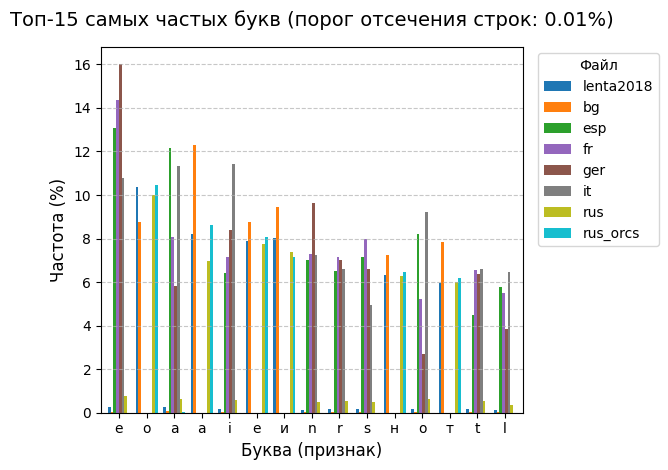

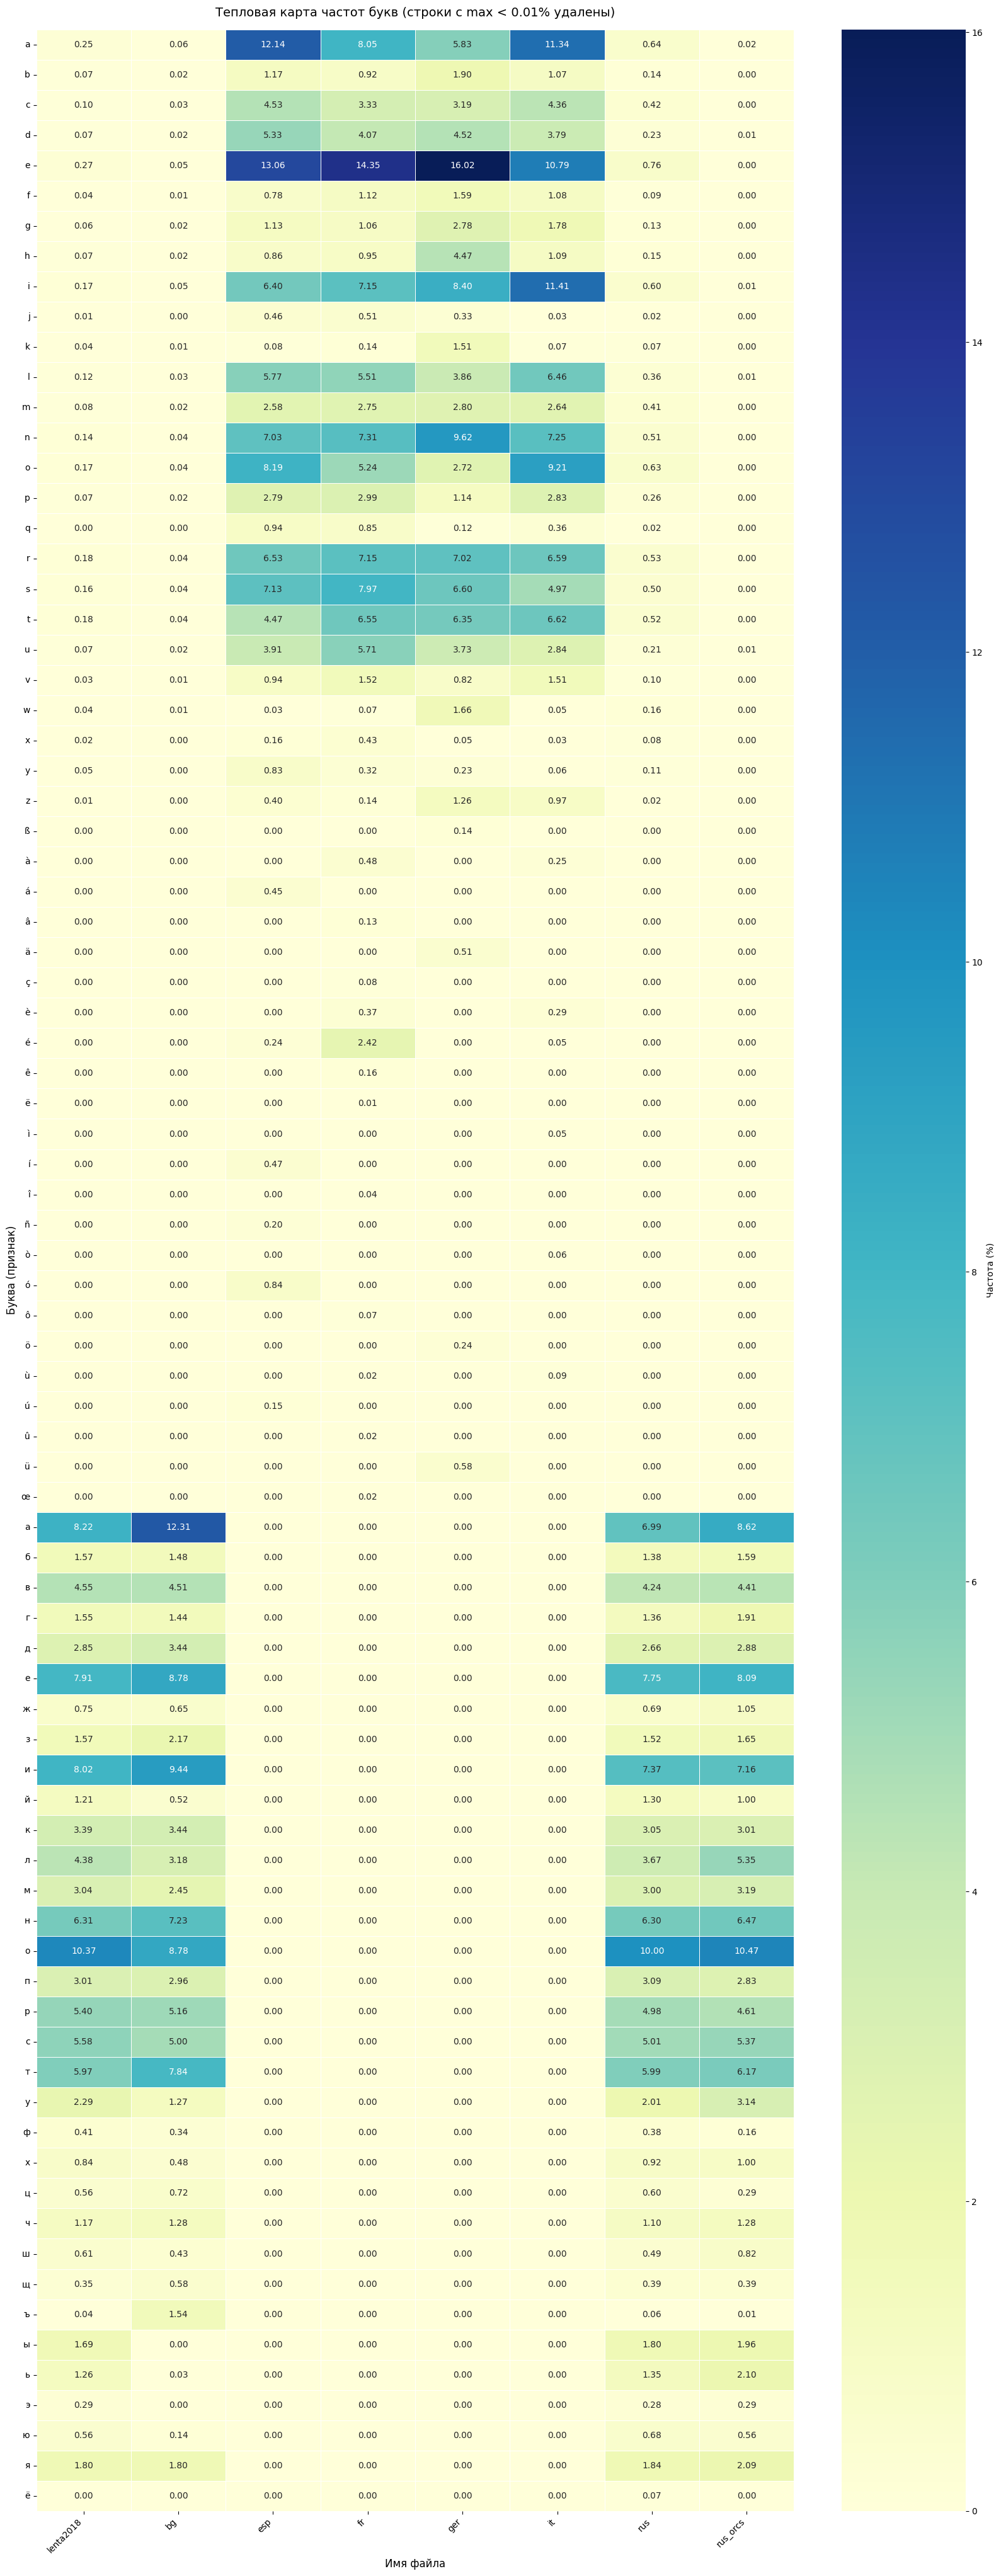

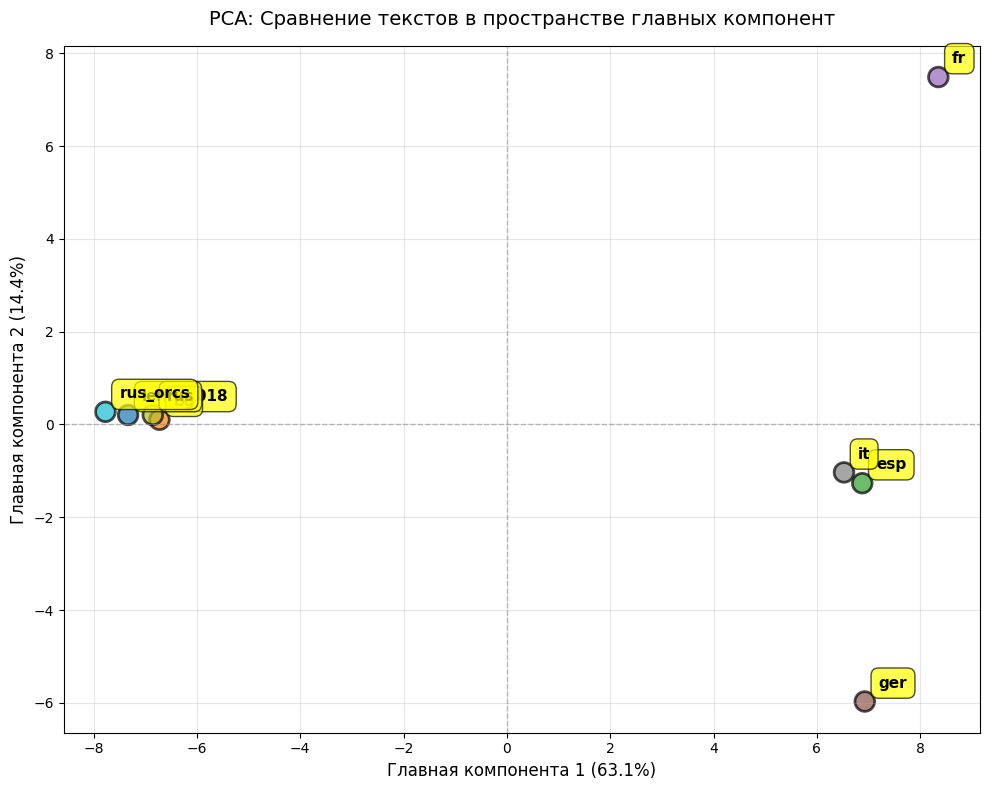

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

# ==========================================
# 1. Настройка пути к папке
# ==========================================
DATA_DIR = Path("data")
THRESHOLD = 0.01  # Порог: удаляем строку, если ВСЕ значения в ней < 0.01

if not DATA_DIR.exists():
    raise FileNotFoundError(f"❌ Папка '{DATA_DIR}' не найдена. Создайте её рядом с ноутбуком.")

txt_files = list(DATA_DIR.glob("*.txt"))
if not txt_files:
    raise FileNotFoundError(f"❌ В папке '{DATA_DIR}' не найдено ни одного .txt файла.")

print(f"📂 Найдено файлов для анализа: {len(txt_files)}")
print(f"🎯 Правило фильтрации: удаляются только те буквы, частота которых во ВСЕХ файлах < {THRESHOLD}%\n")

# ==========================================
# 2. Функции предобработки и векторизации
# ==========================================
def preprocess_text(text):
    """Приводит к нижнему регистру и оставляет только буквы."""
    return [char for char in text.lower() if char.isalpha()]

def get_letter_frequencies(chars):
    """Считает относительную частоту каждой буквы в процентах."""
    counts = Counter(chars)
    total = sum(counts.values())
    if total == 0:
        return {}
    return {char: (count / total) * 100 for char, count in counts.items()}

# ==========================================
# 3. Чтение и анализ всех файлов
# ==========================================
data = {}

for file_path in txt_files:
    file_name = file_path.stem  # Имя файла без расширения
    
    content = None
    for encoding in ["utf-8", "cp1251", "latin-1"]:
        try:
            content = file_path.read_text(encoding=encoding)
            break
        except UnicodeDecodeError:
            continue
            
    if content and content.strip():
        cleaned_chars = preprocess_text(content)
        data[file_name] = get_letter_frequencies(cleaned_chars)
        print(f"✅ Обработан: {file_path.name}")
    else:
        print(f"⚠️ Пропущен (пустой или не читается): {file_path.name}")

# ==========================================
# 4. Формирование и фильтрация матрицы векторов
# ==========================================
# 1. Создаем DataFrame и заполняем пропуски нулями (корректный вектор)
df = pd.DataFrame(data).fillna(0.0).sort_index()

# 2. ФИЛЬТРАЦИЯ: оставляем только те строки, где МАКСИМАЛЬНОЕ значение >= 0.01
# (Если максимум в строке < 0.01, значит ВСЕ значения в ней < 0.01, и мы такую строку удаляем)
df = df[df.max(axis=1) >= THRESHOLD]

# 3. Округляем для аккуратного вида
df = df.round(2)

if df.empty:
    print(f"\n⚠️ ВНИМАНИЕ: После фильтрации таблица пуста.")
    print(f"   Это значит, что ни одна буква не набрала частоту >= {THRESHOLD}% ни в одном из файлов.")
else:
    print(f"\n✅ Матрица векторов признаков сформирована и очищена от шума.")
    print(f"   Было уникальных букв: {len(pd.DataFrame(data))}")
    print(f"   Осталось букв (строк): {len(df)}")
    print(f"   Количество текстов (столбцов): {len(df.columns)}\n")
    display(df)

    # ==========================================
    # 6. PCA-анализ
    # ==========================================
    print("\n📊 PCA-анализ текстов...")
    
    # Транспонируем матрицу: объекты (файлы) в строках, признаки (буквы) в столбцах
    df_for_pca = df.T
    
    # Нормализуем данные (важно для PCA, чтобы частоты букв были в одном масштабе)
    scaler = StandardScaler()
    df_scaled = scaler.fit_transform(df_for_pca)
    
    # Применяем PCA для снижения до 2 главных компонент
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(df_scaled)
    
    # Создаем DataFrame с результатами PCA
    pca_df = pd.DataFrame({
        'PC1': pca_result[:, 0],
        'PC2': pca_result[:, 1],
        'Файл': df_for_pca.index
    })
    
    print(f"✅ PCA выполнен.")
    print(f"   PC1 объясняет {pca.explained_variance_ratio_[0]*100:.1f}% дисперсии")
    print(f"   PC2 объясняет {pca.explained_variance_ratio_[1]*100:.1f}% дисперсии")
    print(f"   Суммарно: {sum(pca.explained_variance_ratio_)*100:.1f}% дисперсии\n")
    
    display(pca_df)    

    # ==========================================
    # 5. Визуализация
    # ==========================================
    
    # График 1: Топ-15 самых частых букв из оставшихся
    top_letters = df.sum(axis=1).nlargest(min(15, len(df))).index
    df_top = df.loc[top_letters]

    plt.figure(figsize=(14, 7))
    df_top.plot(kind='bar', colormap='tab10', width=0.8)
    plt.title(f'Топ-{len(df_top)} самых частых букв (порог отсечения строк: {THRESHOLD}%)', fontsize=14, pad=15)
    plt.xlabel('Буква (признак)', fontsize=12)
    plt.ylabel('Частота (%)', fontsize=12)
    plt.xticks(rotation=0)
    plt.legend(title='Файл', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # График 2: Тепловая карта оставшегося векторного пространства
    plt.figure(figsize=(max(10, len(data) * 2), max(6, len(df) // 2)))
    
    # vmin=0 гарантирует, что нули будут самым светлым цветом, а не выбиваться из шкалы
    sns.heatmap(df, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=.5, 
                cbar_kws={'label': 'Частота (%)'}, vmin=0)
    
    plt.title(f'Тепловая карта частот букв (строки с max < {THRESHOLD}% удалены)', fontsize=14, pad=15)
    plt.xlabel('Имя файла', fontsize=12)
    plt.ylabel('Буква (признак)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


    # График 3: PCA - распределение текстов в пространстве главных компонент
    plt.figure(figsize=(10, 8))
    
    # Рисуем точки для каждого файла
    scatter = plt.scatter(pca_df['PC1'], pca_df['PC2'], 
                          c=range(len(pca_df)), cmap='tab10', s=200, alpha=0.7, edgecolors='black', linewidth=2)
    
    # Подписываем каждую точку именем файла
    for i, row in pca_df.iterrows():
        plt.annotate(row['Файл'], 
                    xy=(row['PC1'], row['PC2']), 
                    xytext=(10, 10), 
                    textcoords='offset points',
                    fontsize=11,
                    fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.7))
    
    # Добавляем оси и заголовки
    plt.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
    plt.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
    
    plt.xlabel(f'Главная компонента 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    plt.ylabel(f'Главная компонента 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    plt.title('PCA: Сравнение текстов в пространстве главных компонент', fontsize=14, pad=15)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Решение для профессионалов

Ты - профессионал в области аналитики и обработки текстов на естественном языке.  
Напиши программу на языке Питон для среды Jupyter Lab.  
Имеется каталог data, в котором находятся текстовый файлы.   
Необходимо рассчитать статистику встречаемости символов в этих файлах и построить векторное представление файлов. Буквы, для которых частота встречаемости во всех файлах 0.01%, она должна быть исключена из анализа.
Выведи хитмап с частотами оставшихся букв.   
Построй представление данных с использованием PCA. Используй два варианта отображения: со значениями относительных частот встречаемости букв в тексте и с нормализацией значений с использованием StandardScaler. 
Для отображения данных используй библиотеку plotly.express.  
Прежде чем начать решать задачу задай мне возникшие у тебя вопросы.   

In [14]:
# Ячейка 1: Импорт библиотек и настройка окружения
import os
import warnings
from pathlib import Path
from collections import Counter
import unicodedata

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Настройка отображения
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Проверка версий
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")
# print(f"plotly: {px.__version__}")
print(f"scikit-learn: {StandardScaler.__module__.split('.')[0]}")

print("\n✓ Библиотеки загружены")

pandas: 3.0.2
numpy: 2.4.4
scikit-learn: sklearn

✓ Библиотеки загружены


In [15]:
# Ячейка 2: Функции для чтения и обработки файлов
def read_file_with_fallback(filepath, encodings=['utf-8', 'utf-8-sig', 'cp1251']):
    """Чтение файла с попыткой нескольких кодировок"""
    for encoding in encodings:
        try:
            with open(filepath, 'r', encoding=encoding) as f:
                return f.read()
        except (UnicodeDecodeError, UnicodeError):
            continue
    
    warnings.warn(f"Не удалось прочитать файл {filepath} ни в одной из кодировок")
    return None

def extract_letters(text):
    """Извлечение только букв в нижнем регистре с NFC нормализацией"""
    if text is None:
        return []
    
    # NFC нормализация
    text = unicodedata.normalize('NFC', text)
    
    # Извлечение букв в нижнем регистре
    letters = [char.lower() for char in text if char.isalpha()]
    return letters

def calculate_relative_frequencies(letter_counts):
    """Расчет относительных частот"""
    total = sum(letter_counts.values())
    if total == 0:
        return {}
    
    return {char: count / total for char, count in letter_counts.items()}

In [16]:
# Ячейка 3: Чтение данных и расчет частот
data_dir = Path('data')

# Проверка существования каталога
if not data_dir.exists():
    raise FileNotFoundError(f"Каталог {data_dir} не найден. Создайте его и поместите текстовые файлы.")

# Сбор всех текстовых файлов рекурсивно
text_files = list(data_dir.rglob('*.txt'))

if len(text_files) == 0:
    raise FileNotFoundError(f"В каталоге {data_dir} не найдено файлов .txt")

print(f"Найдено файлов: {len(text_files)}")
print(f"Файлы: {[f.name for f in text_files[:10]]}{'...' if len(text_files) > 10 else ''}")

# Обработка каждого файла
file_data = []
corpus_letter_counts = Counter()

for filepath in text_files:
    text = read_file_with_fallback(filepath)
    
    if text is None:
        print(f"⚠ Пропущен файл: {filepath.name}")
        continue
    
    letters = extract_letters(text)
    
    if len(letters) == 0:
        print(f"⚠ Файл {filepath.name} не содержит букв, пропущен")
        continue
    
    # Подсчет частот для файла
    letter_counts = Counter(letters)
    relative_freq = calculate_relative_frequencies(letter_counts)
    
    # Добавление к общему корпусу
    corpus_letter_counts.update(letter_counts)
    
    file_data.append({
        'filename': filepath.name,
        'filepath': str(filepath),
        'total_letters': len(letters),
        'letter_counts': letter_counts,
        'relative_freq': relative_freq
    })

print(f"\n✓ Успешно обработано файлов: {len(file_data)}")
print(f"Общее количество букв в корпусе: {sum(corpus_letter_counts.values())}")

Найдено файлов: 8
Файлы: ['lenta2018.txt', 'bg.txt', 'esp.txt', 'fr.txt', 'ger.txt', 'it.txt', 'rus.txt', 'rus_orcs.txt']

✓ Успешно обработано файлов: 8
Общее количество букв в корпусе: 7324363


In [17]:
# Ячейка 4: Фильтрация редких букв и создание матрицы частот
# Расчет общей частоты каждой буквы в корпусе
total_corpus_letters = sum(corpus_letter_counts.values())
corpus_relative_freq = {
    char: count / total_corpus_letters 
    for char, count in corpus_letter_counts.items()
}

# Порог 0.01% = 0.0001
threshold = 0.0001

# Определение букв для исключения
excluded_letters = {
    char: freq 
    for char, freq in corpus_relative_freq.items() 
    if freq < threshold
}

included_letters = {
    char: freq 
    for char, freq in corpus_relative_freq.items() 
    if freq >= threshold
}

print(f"Порог частоты: {threshold * 100:.4f}%")
print(f"Уникальных букв в корпусе: {len(corpus_relative_freq)}")
print(f"Букв для исключения (< {threshold * 100:.4f}%): {len(excluded_letters)}")
print(f"Букв для анализа (≥ {threshold * 100:.4f}%): {len(included_letters)}")

if excluded_letters:
    print(f"\nИсключенные буквы:")
    for char, freq in sorted(excluded_letters.items(), key=lambda x: x[1], reverse=True):
        print(f"  '{char}': {freq * 100:.6f}%")

# Создание матрицы частот (строки - файлы, столбцы - буквы)
# Сортировка букв по убыванию общей частоты
sorted_letters = sorted(included_letters.keys(), 
                        key=lambda x: included_letters[x], 
                        reverse=True)

# Создание DataFrame
matrix_data = []
for file_info in file_data:
    row = {'filename': file_info['filename']}
    for letter in sorted_letters:
        # Относительная частота буквы в файле
        row[letter] = file_info['relative_freq'].get(letter, 0.0)
    matrix_data.append(row)

freq_matrix = pd.DataFrame(matrix_data).set_index('filename')

print(f"\n✓ Матрица частот создана: {freq_matrix.shape[0]} файлов × {freq_matrix.shape[1]} букв")

# Сохранение матрицы
freq_matrix.to_csv('char_freq_matrix.csv', encoding='utf-8-sig')
print("✓ Матрица сохранена в char_freq_matrix.csv")

Порог частоты: 0.0100%
Уникальных букв в корпусе: 180
Букв для исключения (< 0.0100%): 107
Букв для анализа (≥ 0.0100%): 73

Исключенные буквы:
  'ç': 0.008096%
  'ё': 0.007796%
  'ô': 0.006349%
  'ò': 0.006212%
  'ì': 0.004901%
  'î': 0.003604%
  'û': 0.002144%
  'œ': 0.001816%
  'ë': 0.001324%
  'ï': 0.000806%
  'ª': 0.000246%
  'є': 0.000164%
  'ğ': 0.000164%
  '日': 0.000109%
  '猫': 0.000109%
  '島': 0.000109%
  'ま': 0.000096%
  '熊': 0.000082%
  '新': 0.000068%
  '聞': 0.000068%
  'の': 0.000068%
  'і': 0.000055%
  '本': 0.000055%
  'あ': 0.000055%
  'り': 0.000055%
  '部': 0.000055%
  'ć': 0.000055%
  '天': 0.000041%
  '草': 0.000041%
  'こ': 0.000041%
  'º': 0.000041%
  'ã': 0.000041%
  'š': 0.000041%
  'ř': 0.000041%
  'ø': 0.000027%
  'ι': 0.000027%
  'ѕ': 0.000027%
  'ら': 0.000027%
  '淡': 0.000027%
  '々': 0.000027%
  'と': 0.000027%
  '白': 0.000027%
  '菜': 0.000027%
  '上': 0.000027%
  '湯': 0.000027%
  '博': 0.000027%
  '物': 0.000027%
  '館': 0.000027%
  'わ': 0.000027%
  '社': 0.000027%
  'ね':

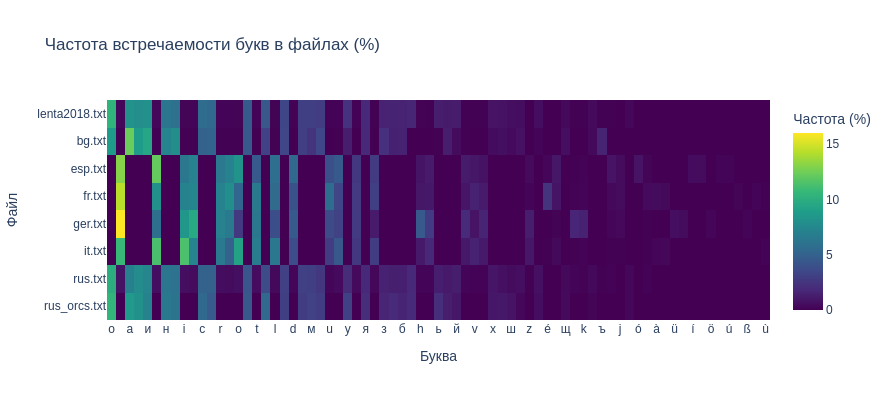


✓ Хитмап построен для 73 букв в 8 файлах


In [18]:
# Ячейка 5: Хитмап частот букв
# Конвертация в проценты для отображения
freq_matrix_pct = freq_matrix * 100

# Создание хитмапа
fig_heatmap = px.imshow(
    freq_matrix_pct.values,
    x=freq_matrix_pct.columns,
    y=freq_matrix_pct.index,
    color_continuous_scale='Viridis',
    title='Частота встречаемости букв в файлах (%)',
    labels={'x': 'Буква', 'y': 'Файл', 'color': 'Частота (%)'},
    aspect='auto'
)

fig_heatmap.update_layout(
    height=max(400, len(freq_matrix) * 25),
    width=max(800, len(sorted_letters) * 40),
    xaxis_title='Буква',
    yaxis_title='Файл'
)

fig_heatmap.show()

print(f"\n✓ Хитмап построен для {len(sorted_letters)} букв в {len(freq_matrix)} файлах")

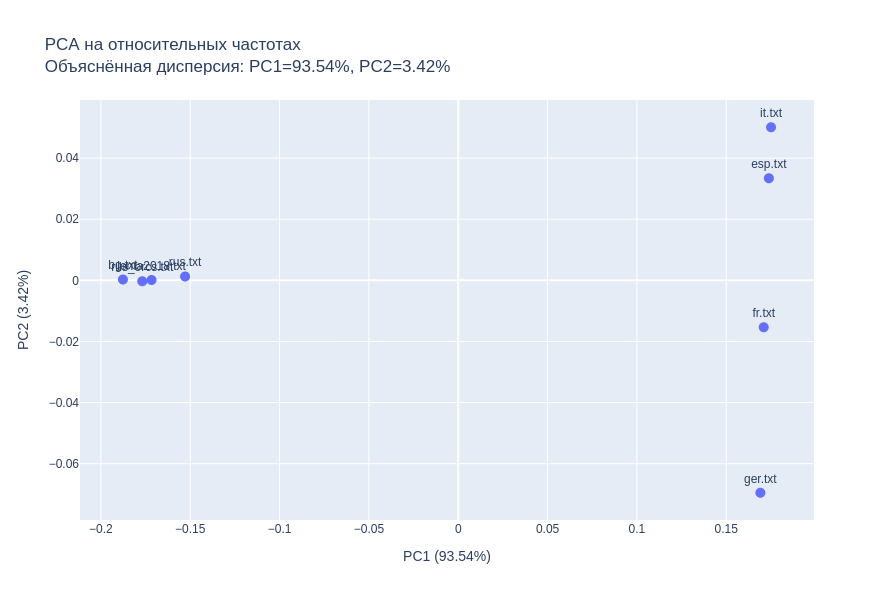

✓ PCA без нормализации построен
  Суммарная объяснённая дисперсия (2 компоненты): 96.96%


In [19]:
# Ячейка 6: PCA на относительных частотах (без нормализации)
# Подготовка данных для PCA
X_raw = freq_matrix.values
filenames = freq_matrix.index.tolist()

# PCA без нормализации
pca_raw = PCA(n_components=2)
X_pca_raw = pca_raw.fit_transform(X_raw)

# Создание DataFrame для визуализации
pca_df_raw = pd.DataFrame({
    'PC1': X_pca_raw[:, 0],
    'PC2': X_pca_raw[:, 1],
    'filename': filenames
})

# График PCA без нормализации
fig_pca_raw = px.scatter(
    pca_df_raw,
    x='PC1',
    y='PC2',
    text='filename',
    title=f'PCA на относительных частотах<br>'
          f'Объяснённая дисперсия: PC1={pca_raw.explained_variance_ratio_[0]:.2%}, '
          f'PC2={pca_raw.explained_variance_ratio_[1]:.2%}',
    labels={'PC1': f'PC1 ({pca_raw.explained_variance_ratio_[0]:.2%})',
            'PC2': f'PC2 ({pca_raw.explained_variance_ratio_[1]:.2%})'}
)

fig_pca_raw.update_traces(textposition='top center', marker_size=10)
fig_pca_raw.update_layout(height=600, width=900)
fig_pca_raw.show()

print(f"✓ PCA без нормализации построен")
print(f"  Суммарная объяснённая дисперсия (2 компоненты): {sum(pca_raw.explained_variance_ratio_):.2%}")

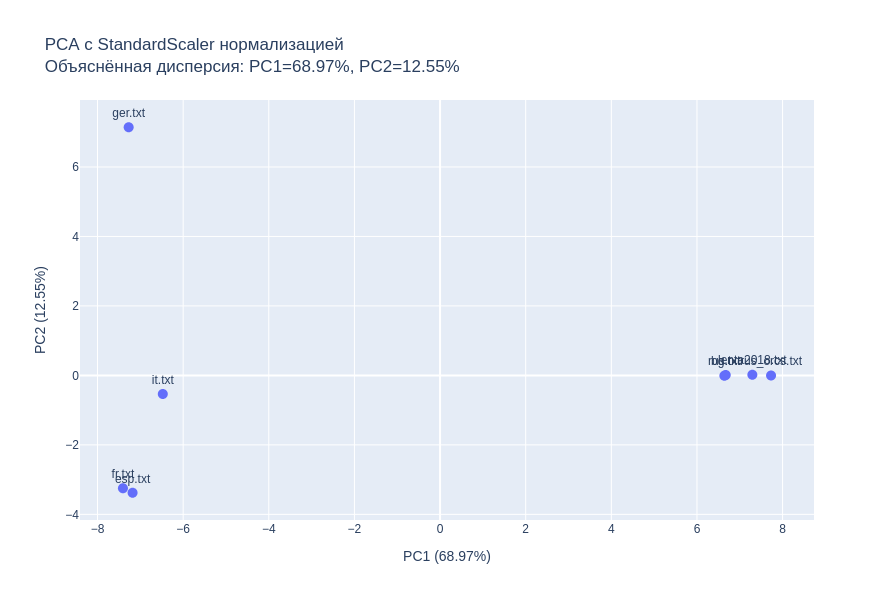

✓ PCA с нормализацией построен
  Суммарная объяснённая дисперсия (2 компоненты): 81.52%


In [20]:
# Ячейка 7: PCA с нормализацией StandardScaler
# Нормализация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# PCA на нормализованных данных
pca_scaled = PCA(n_components=2)
X_pca_scaled = pca_scaled.fit_transform(X_scaled)

# Создание DataFrame для визуализации
pca_df_scaled = pd.DataFrame({
    'PC1': X_pca_scaled[:, 0],
    'PC2': X_pca_scaled[:, 1],
    'filename': filenames
})

# График PCA с нормализацией
fig_pca_scaled = px.scatter(
    pca_df_scaled,
    x='PC1',
    y='PC2',
    text='filename',
    title=f'PCA с StandardScaler нормализацией<br>'
          f'Объяснённая дисперсия: PC1={pca_scaled.explained_variance_ratio_[0]:.2%}, '
          f'PC2={pca_scaled.explained_variance_ratio_[1]:.2%}',
    labels={'PC1': f'PC1 ({pca_scaled.explained_variance_ratio_[0]:.2%})',
            'PC2': f'PC2 ({pca_scaled.explained_variance_ratio_[1]:.2%})'}
)

fig_pca_scaled.update_traces(textposition='top center', marker_size=10)
fig_pca_scaled.update_layout(height=600, width=900)
fig_pca_scaled.show()

print(f"✓ PCA с нормализацией построен")
print(f"  Суммарная объяснённая дисперсия (2 компоненты): {sum(pca_scaled.explained_variance_ratio_):.2%}")

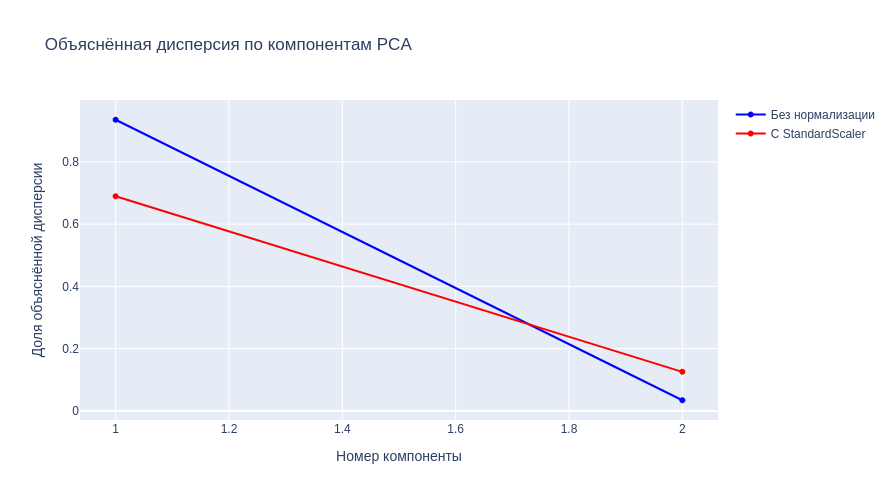


📊 Сравнение методов PCA:
           Метод   PC1 (%)   PC2 (%)  Сумма PC1+PC2 (%)
Без нормализации 93.540950  3.418072          96.959022
С StandardScaler 68.971841 12.550478          81.522319

✓ Анализ завершен


In [21]:
# Ячейка 8: Сравнение методов и анализ объяснённой дисперсии
# График объяснённой дисперсии по компонентам
fig_variance = go.Figure()

fig_variance.add_trace(go.Scatter(
    x=list(range(1, len(pca_raw.explained_variance_ratio_) + 1)),
    y=pca_raw.explained_variance_ratio_,
    mode='lines+markers',
    name='Без нормализации',
    line=dict(color='blue')
))

fig_variance.add_trace(go.Scatter(
    x=list(range(1, len(pca_scaled.explained_variance_ratio_) + 1)),
    y=pca_scaled.explained_variance_ratio_,
    mode='lines+markers',
    name='С StandardScaler',
    line=dict(color='red')
))

fig_variance.update_layout(
    title='Объяснённая дисперсия по компонентам PCA',
    xaxis_title='Номер компоненты',
    yaxis_title='Доля объяснённой дисперсии',
    height=500,
    width=800
)

fig_variance.show()

# Сводная таблица сравнения
comparison_df = pd.DataFrame({
    'Метод': ['Без нормализации', 'С StandardScaler'],
    'PC1 (%)': [pca_raw.explained_variance_ratio_[0] * 100, 
                pca_scaled.explained_variance_ratio_[0] * 100],
    'PC2 (%)': [pca_raw.explained_variance_ratio_[1] * 100, 
                pca_scaled.explained_variance_ratio_[1] * 100],
    'Сумма PC1+PC2 (%)': [sum(pca_raw.explained_variance_ratio_) * 100, 
                          sum(pca_scaled.explained_variance_ratio_) * 100]
})

print("\n📊 Сравнение методов PCA:")
print(comparison_df.to_string(index=False))

print("\n✓ Анализ завершен")

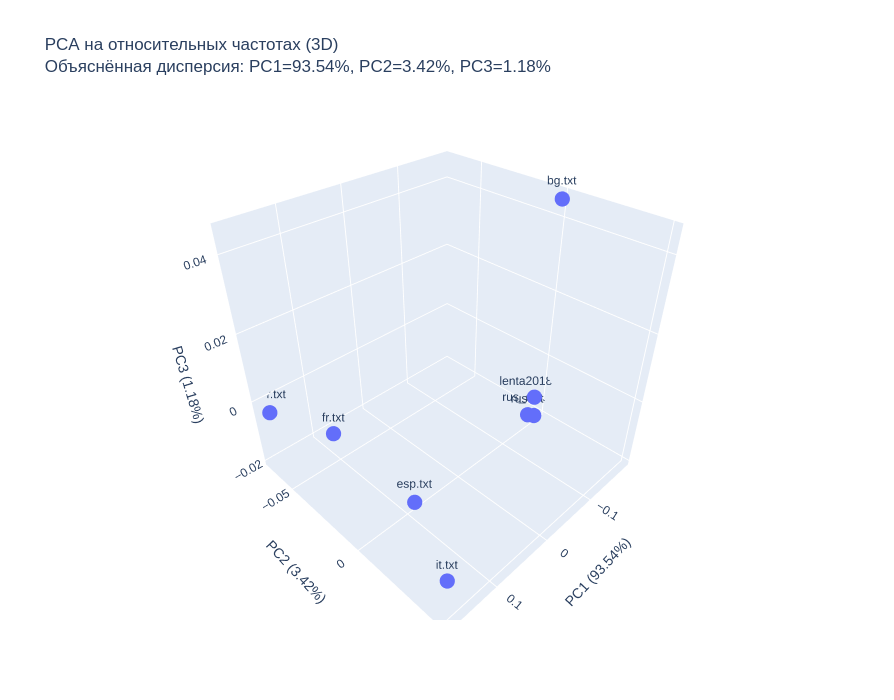

✓ PCA без нормализации построен (3D)
  Суммарная объяснённая дисперсия (3 компоненты): 98.14%


In [22]:
# Ячейка 6: PCA на относительных частотах (без нормализации) - 3D
# Подготовка данных для PCA
X_raw = freq_matrix.values
filenames = freq_matrix.index.tolist()

# PCA без нормализации - 3 компоненты
pca_raw = PCA(n_components=3)
X_pca_raw = pca_raw.fit_transform(X_raw)

# Создание DataFrame для визуализации
pca_df_raw = pd.DataFrame({
    'PC1': X_pca_raw[:, 0],
    'PC2': X_pca_raw[:, 1],
    'PC3': X_pca_raw[:, 2],
    'filename': filenames
})

# График PCA без нормализации - 3D
fig_pca_raw = px.scatter_3d(
    pca_df_raw,
    x='PC1',
    y='PC2',
    z='PC3',
    text='filename',
    title=f'PCA на относительных частотах (3D)<br>'
          f'Объяснённая дисперсия: PC1={pca_raw.explained_variance_ratio_[0]:.2%}, '
          f'PC2={pca_raw.explained_variance_ratio_[1]:.2%}, '
          f'PC3={pca_raw.explained_variance_ratio_[2]:.2%}',
    labels={'PC1': f'PC1 ({pca_raw.explained_variance_ratio_[0]:.2%})',
            'PC2': f'PC2 ({pca_raw.explained_variance_ratio_[1]:.2%})',
            'PC3': f'PC3 ({pca_raw.explained_variance_ratio_[2]:.2%})'}
)

fig_pca_raw.update_traces(textposition='top center', marker_size=5)
fig_pca_raw.update_layout(height=700, width=1000)
fig_pca_raw.show()

print(f"✓ PCA без нормализации построен (3D)")
print(f"  Суммарная объяснённая дисперсия (3 компоненты): {sum(pca_raw.explained_variance_ratio_):.2%}")

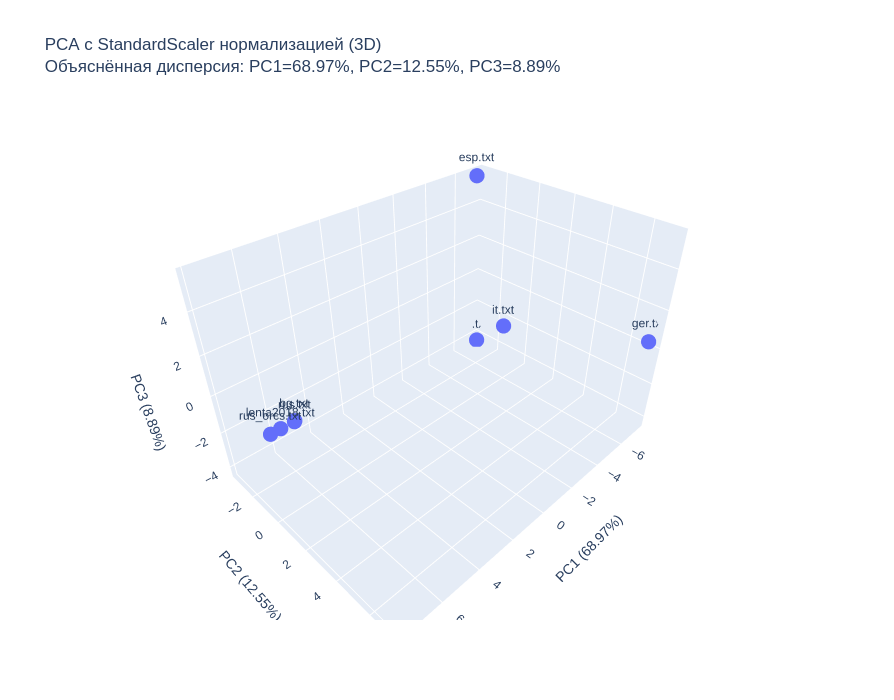

✓ PCA с нормализацией построен (3D)
  Суммарная объяснённая дисперсия (3 компоненты): 90.41%


In [23]:
# Ячейка 7: PCA с нормализацией StandardScaler - 3D
# Нормализация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# PCA на нормализованных данных - 3 компоненты
pca_scaled = PCA(n_components=3)
X_pca_scaled = pca_scaled.fit_transform(X_scaled)

# Создание DataFrame для визуализации
pca_df_scaled = pd.DataFrame({
    'PC1': X_pca_scaled[:, 0],
    'PC2': X_pca_scaled[:, 1],
    'PC3': X_pca_scaled[:, 2],
    'filename': filenames
})

# График PCA с нормализацией - 3D
fig_pca_scaled = px.scatter_3d(
    pca_df_scaled,
    x='PC1',
    y='PC2',
    z='PC3',
    text='filename',
    title=f'PCA с StandardScaler нормализацией (3D)<br>'
          f'Объяснённая дисперсия: PC1={pca_scaled.explained_variance_ratio_[0]:.2%}, '
          f'PC2={pca_scaled.explained_variance_ratio_[1]:.2%}, '
          f'PC3={pca_scaled.explained_variance_ratio_[2]:.2%}',
    labels={'PC1': f'PC1 ({pca_scaled.explained_variance_ratio_[0]:.2%})',
            'PC2': f'PC2 ({pca_scaled.explained_variance_ratio_[1]:.2%})',
            'PC3': f'PC3 ({pca_scaled.explained_variance_ratio_[2]:.2%})'}
)

fig_pca_scaled.update_traces(textposition='top center', marker_size=5)
fig_pca_scaled.update_layout(height=700, width=1000)
fig_pca_scaled.show()

print(f"✓ PCA с нормализацией построен (3D)")
print(f"  Суммарная объяснённая дисперсия (3 компоненты): {sum(pca_scaled.explained_variance_ratio_):.2%}")

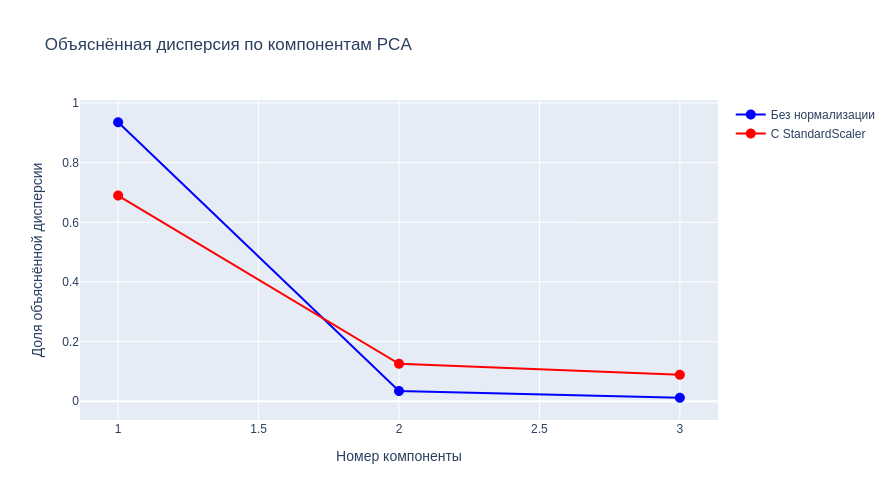


📊 Сравнение методов PCA:
           Метод   PC1 (%)   PC2 (%)  PC3 (%)  Сумма PC1+PC2+PC3 (%)
Без нормализации 93.540950  3.418072 1.179614              98.138635
С StandardScaler 68.971841 12.550478 8.890277              90.412595

✓ Анализ завершен


In [24]:
# Ячейка 8: Сравнение методов и анализ объяснённой дисперсии
# График объяснённой дисперсии по компонентам
fig_variance = go.Figure()

fig_variance.add_trace(go.Scatter(
    x=list(range(1, len(pca_raw.explained_variance_ratio_) + 1)),
    y=pca_raw.explained_variance_ratio_,
    mode='lines+markers',
    name='Без нормализации',
    line=dict(color='blue'),
    marker=dict(size=10)
))

fig_variance.add_trace(go.Scatter(
    x=list(range(1, len(pca_scaled.explained_variance_ratio_) + 1)),
    y=pca_scaled.explained_variance_ratio_,
    mode='lines+markers',
    name='С StandardScaler',
    line=dict(color='red'),
    marker=dict(size=10)
))

fig_variance.update_layout(
    title='Объяснённая дисперсия по компонентам PCA',
    xaxis_title='Номер компоненты',
    yaxis_title='Доля объяснённой дисперсии',
    height=500,
    width=800
)

fig_variance.show()

# Сводная таблица сравнения
comparison_df = pd.DataFrame({
    'Метод': ['Без нормализации', 'С StandardScaler'],
    'PC1 (%)': [pca_raw.explained_variance_ratio_[0] * 100, 
                pca_scaled.explained_variance_ratio_[0] * 100],
    'PC2 (%)': [pca_raw.explained_variance_ratio_[1] * 100, 
                pca_scaled.explained_variance_ratio_[1] * 100],
    'PC3 (%)': [pca_raw.explained_variance_ratio_[2] * 100, 
                pca_scaled.explained_variance_ratio_[2] * 100],
    'Сумма PC1+PC2+PC3 (%)': [sum(pca_raw.explained_variance_ratio_) * 100, 
                              sum(pca_scaled.explained_variance_ratio_) * 100]
})

print("\n📊 Сравнение методов PCA:")
print(comparison_df.to_string(index=False))

print("\n✓ Анализ завершен")